Epoch 1/150
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.5541 - loss: 0.6706 - val_accuracy: 0.6320 - val_loss: 0.6711
Epoch 2/150
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6208 - loss: 0.6443 - val_accuracy: 0.6543 - val_loss: 0.6472
Epoch 3/150
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6348 - loss: 0.6338 - val_accuracy: 0.6543 - val_loss: 0.6489
Epoch 4/150
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6572 - loss: 0.6282 - val_accuracy: 0.6097 - val_loss: 0.6520
Epoch 5/150
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6518 - loss: 0.6247 - val_accuracy: 0.6468 - val_loss: 0.6381
Epoch 6/150
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6347 - loss: 0.6270 - val_accuracy: 0.6357 - val_loss: 0.6462
Epoch 7/150
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6538 - loss: 0.6173 - val_accuracy: 0.6320 - val_loss: 0.6467
Epoch 8/150
152/152 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6676 - loss: 0.6141 - val_accu


Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.84      0.90       269
           1       0.90      0.99      0.94       403

    accuracy                           0.93       672
   macro avg       0.94      0.91      0.92       672
weighted avg       0.93      0.93      0.92       672

Confusion Matrix:
 [[225  44]
 [  6 397]]

💾 Model saved at: palm_lab_ann_best.h5


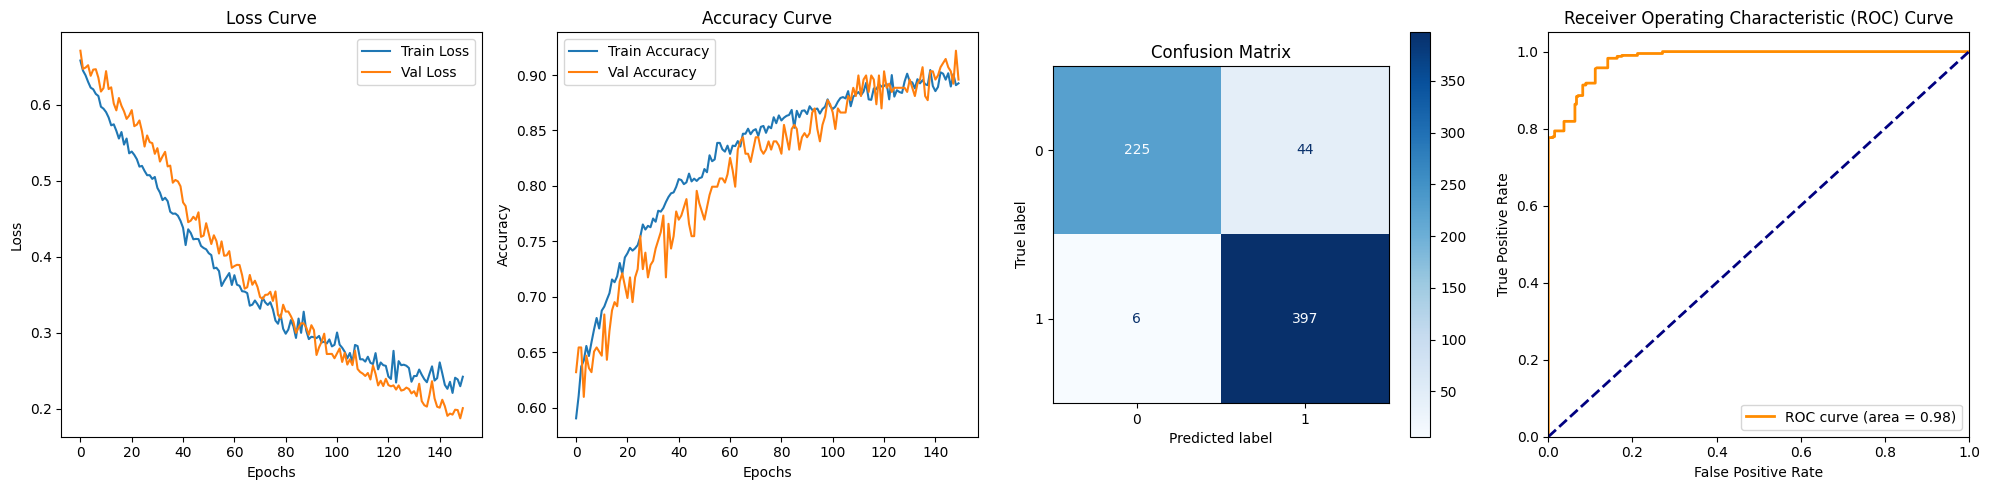

In [ ]:
# -------------------------------
# ✅ Improved ANN for Anemia Detection (High Accuracy Version)
# -------------------------------

import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, ConfusionMatrixDisplay
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# --- Load dataset ---
data = pd.read_csv('palm_lab_features.csv')

# Features and labels
X = data[['L_mean', 'A_mean', 'B_mean']].values
y = data['label'].values

# --- Normalize ---
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# --- Split into train, validation, and test ---
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.1, random_state=42, stratify=y_train
)

# --- Model: Based on your original high-accuracy architecture ---
model = models.Sequential([
    layers.Input(shape=(3,)),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

# --- Compile ---
model.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# --- Callbacks ---
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=8, restore_best_weights=True
)

# --- Train ---
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=150,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)

# --- Evaluate ---
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"\n✅ Test Accuracy: {test_acc*100:.2f}%")

# --- Predictions ---
y_pred_proba = model.predict(X_test)
y_pred = (y_pred_proba >= 0.5).astype(int)

print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

# --- Save Model ---
save_path = 'palm_lab_ann_best.h5'
model.save(save_path)
print(f"\n💾 Model saved at: {save_path}")

# --- Plot Results ---
plt.figure(figsize=(20, 5))

# Plot Loss & Accuracy
plt.subplot(1, 4, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 4, 2)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Accuracy Curve')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Plot Confusion Matrix
plt.subplot(1, 4, 3)
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['0', '1'])
disp.plot(ax=plt.gca(), cmap=plt.cm.Blues)
plt.title('Confusion Matrix')

# Plot ROC Curve
plt.subplot(1, 4, 4)
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")

plt.tight_layout()
plt.savefig('model_performance_plots.png') # Save the figure
plt.show()

Epoch 1/150
152/152 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.5871 - loss: 0.6665 - val_accuracy: 0.6208 - val_loss: 0.6645
Epoch 2/150
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6050 - loss: 0.6474 - val_accuracy: 0.6208 - val_loss: 0.6653
Epoch 3/150
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6407 - loss: 0.6387 - val_accuracy: 0.6208 - val_loss: 0.6575
Epoch 4/150
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6240 - loss: 0.6445 - val_accuracy: 0.6394 - val_loss: 0.6552
Epoch 5/150
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6279 - loss: 0.6444 - val_accuracy: 0.6468 - val_loss: 0.6536
Epoch 6/150
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6085 - loss: 0.6538 - val_accuracy: 0.6208 - val_loss: 0.6588
Epoch 7/150
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6289 - loss: 0.6425 - val_accuracy: 0.6134 - val_loss: 0.6542
Epoch 8/150
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6279 - loss: 0.6354 - val_accu


Classification Report:
               precision    recall  f1-score   support

           0       0.72      0.59      0.65       269
           1       0.75      0.85      0.80       403

    accuracy                           0.74       672
   macro avg       0.74      0.72      0.72       672
weighted avg       0.74      0.74      0.74       672

Confusion Matrix:
 [[158 111]
 [ 61 342]]

💾 Model saved at: palm_lab_unet_experiment.h5


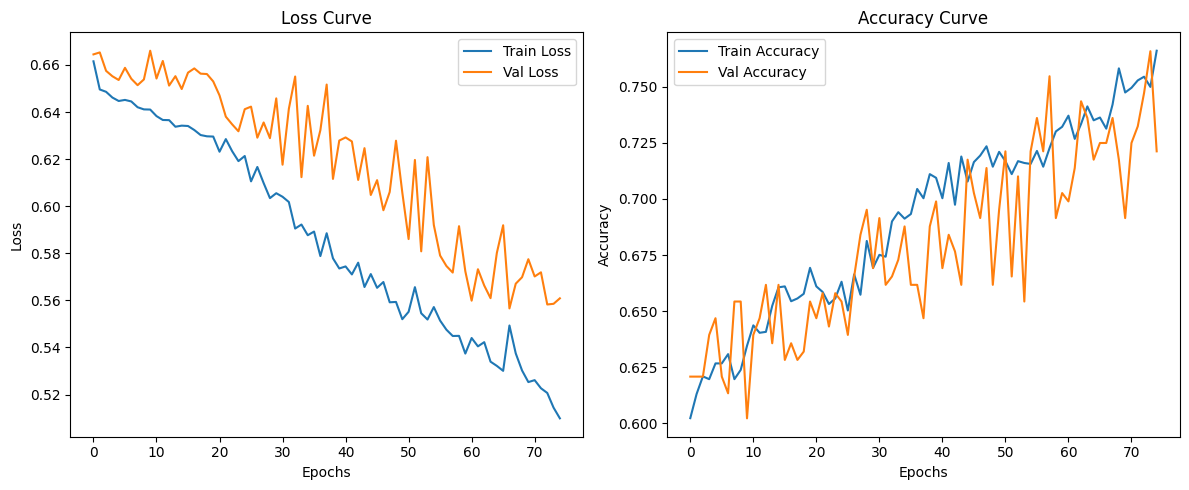

In [ ]:
# -------------------------------
# ✅ Experiment with UNet-like structure for Anemia Detection (Non-standard approach for tabular data)
# -------------------------------

import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, Input
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# --- Load dataset ---
data = pd.read_csv('palm_lab_features.csv')

# Features and labels
X = data[['L_mean', 'A_mean', 'B_mean']].values
y = data['label'].values

# --- Normalize ---
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# --- Split into train, validation, and test ---
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.1, random_state=42, stratify=y_train
)

# Reshape data for UNet-like input (adding dummy dimensions)
# This is not how UNet is typically used and is done purely for demonstration
X_train = X_train.reshape(-1, 3, 1, 1)
X_val = X_val.reshape(-1, 3, 1, 1)
X_test = X_test.reshape(-1, 3, 1, 1)


# --- Model: Simplified UNet-like structure for tabular data ---
# This is a highly simplified version to fit tabular data and is not a true UNet
input_layer = Input(shape=(3, 1, 1))

# Contracting Path (Encoder)
conv1 = layers.Conv2D(32, (1, 1), activation='relu', padding='same')(input_layer)
pool1 = layers.MaxPooling2D((1, 1))(conv1)

conv2 = layers.Conv2D(64, (1, 1), activation='relu', padding='same')(pool1)
pool2 = layers.MaxPooling2D((1, 1))(conv2)

# Bottleneck
conv_bottle = layers.Conv2D(128, (1, 1), activation='relu', padding='same')(pool2)

# Expanding Path (Decoder)
up1 = layers.Conv2DTranspose(64, (1, 1), strides=(1, 1), padding='same')(conv_bottle)
concat1 = layers.concatenate([up1, conv2]) # Simplified concatenation

up2 = layers.Conv2DTranspose(32, (1, 1), strides=(1, 1), padding='same')(concat1)
concat2 = layers.concatenate([up2, conv1]) # Simplified concatenation

# Output layer - flatten and use Dense for binary classification
flatten = layers.Flatten()(concat2)
output_layer = layers.Dense(1, activation='sigmoid')(flatten)


model = models.Model(inputs=input_layer, outputs=output_layer)


# --- Compile ---
model.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# --- Callbacks ---
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=8, restore_best_weights=True
)

# --- Train ---
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=150,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)

# --- Evaluate ---
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"\n✅ Test Accuracy: {test_acc*100:.2f}%")

# --- Predictions ---
y_pred = (model.predict(X_test) >= 0.5).astype(int)

print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

# --- Save Model ---
save_path = 'palm_lab_unet_experiment.h5'
model.save(save_path)
print(f"\n💾 Model saved at: {save_path}")

# --- Plot Loss & Accuracy ---
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Accuracy Curve')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

Epoch 1/150
152/152 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.5793 - loss: 0.6911 - val_accuracy: 0.5985 - val_loss: 0.6854
Epoch 2/150
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5971 - loss: 0.6836 - val_accuracy: 0.5985 - val_loss: 0.6794
Epoch 3/150
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5835 - loss: 0.6805 - val_accuracy: 0.5985 - val_loss: 0.6760
Epoch 4/150
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6083 - loss: 0.6731 - val_accuracy: 0.5985 - val_loss: 0.6747
Epoch 5/150
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6128 - loss: 0.6697 - val_accuracy: 0.5985 - val_loss: 0.6740
Epoch 6/150
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6032 - loss: 0.6732 - val_accuracy: 0.5985 - val_loss: 0.6738
Epoch 7/150
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6028 - loss: 0.6732 - val_accuracy: 0.5985 - val_loss: 0.6738
Epoch 8/150
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5945 - loss: 0.6749 - val_ac

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00       269
           1       0.60      1.00      0.75       403

    accuracy                           0.60       672
   macro avg       0.30      0.50      0.37       672
weighted avg       0.36      0.60      0.45       672

Confusion Matrix:
 [[  0 269]
 [  0 403]]

💾 Model saved at: palm_lab_transformer_experiment.h5


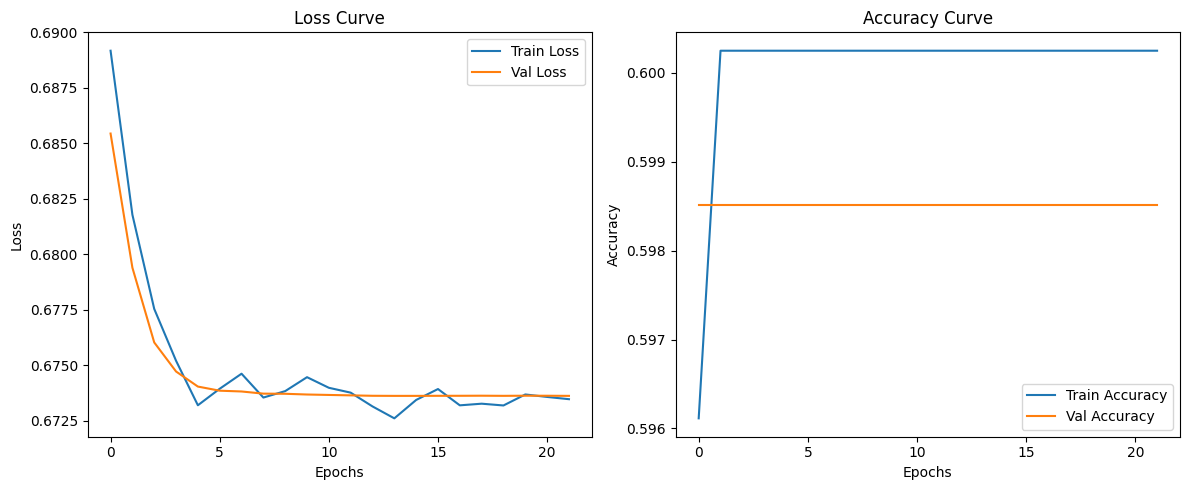

In [ ]:
# -------------------------------
# ✅ Experiment with Transformer-like structure for Anemia Detection (Non-standard approach for tabular data)
# -------------------------------

import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, Input
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# --- Load dataset ---
data = pd.read_csv('palm_lab_features.csv')

# Features and labels
X = data[['L_mean', 'A_mean', 'B_mean']].values
y = data['label'].values

# --- Normalize ---
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# --- Split into train, validation, and test ---
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.1, random_state=42, stratify=y_train
)

# Reshape data for Transformer input (treating features as a sequence)
# Each sample is a sequence of 3 features
X_train = X_train.reshape(-1, 3, 1)
X_val = X_val.reshape(-1, 3, 1)
X_test = X_test.reshape(-1, 3, 1)


# --- Model: Simplified Transformer-like structure for tabular data ---
def transformer_block(x, num_heads, ff_dim, dropout_rate=0.1):
    # Multi-head attention
    attn_output = layers.MultiHeadAttention(num_heads=num_heads, key_dim=x.shape[-1])(x, x)
    attn_output = layers.Dropout(dropout_rate)(attn_output)
    attn_output = layers.LayerNormalization(epsilon=1e-6)(x + attn_output)

    # Feed-forward network
    ffn_output = layers.Dense(ff_dim, activation="relu")(attn_output)
    ffn_output = layers.Dense(x.shape[-1])(ffn_output)
    ffn_output = layers.Dropout(dropout_rate)(ffn_output)
    return layers.LayerNormalization(epsilon=1e-6)(attn_output + ffn_output)

input_layer = Input(shape=(3, 1)) # Input shape is (sequence_length, feature_dimension)

# Add positional encoding (simplified)
positional_encoding = layers.Embedding(input_dim=3, output_dim=1)(tf.range(start=0, limit=3, delta=1))
x = input_layer + positional_encoding

# Transformer blocks
x = transformer_block(x, num_heads=1, ff_dim=32)
x = transformer_block(x, num_heads=1, ff_dim=32)


# Global average pooling and classification head
x = layers.GlobalAveragePooling1D()(x)
x = layers.Dropout(0.4)(x)
output_layer = layers.Dense(1, activation="sigmoid")(x)


model = models.Model(inputs=input_layer, outputs=output_layer)


# --- Compile ---
model.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# --- Callbacks ---
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=8, restore_best_weights=True
)

# --- Train ---
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=150,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)

# --- Evaluate ---
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"\n✅ Test Accuracy: {test_acc*100:.2f}%")

# --- Predictions ---
y_pred = (model.predict(X_test) >= 0.5).astype(int)

print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

# --- Save Model ---
save_path = 'palm_lab_transformer_experiment.h5'
model.save(save_path)
print(f"\n💾 Model saved at: {save_path}")

# --- Plot Loss & Accuracy ---
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Accuracy Curve')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()